# Step 3 — Satellite availability on the frost nights

Spec: `CLAUDE.md` §6 Step 3. **This is the step most likely to kill the study**, and it is where
**K4** is tested: is clear-sky sampling so biased that the nights the satellite sees are not the
nights that matter?

Radiative frost needs clear skies, so availability on frost nights *should* be higher than on
ordinary nights. That is a prediction, not an assumption, and it is tested here.

**Screens are the products' own.** Every flag definition below is read from the Earth Engine
catalogue's bitmask metadata, never invented (§6 Step 3). Extraction is in `notebooks/thermal.py`
and `notebooks/extract_availability.py`.

**Three extraction traps were hit and are recorded here rather than buried**, because each
produced a believable wrong answer rather than an error — the pattern §8 item 10 exists for:

1. **MODIS masks its QC band where quality is best.** In `MOD11A1`/`MYD11A1` the `QC_Night` band
   is masked wherever its value is 0, which is "LST produced, good quality". Reading a masked QC
   as unusable would discard two-thirds of the valid retrievals, and precisely the best ones.
   Verified over a test season: 705 station-nights had LST present with QC masked, 716 had QC
   present with LST absent, 343 had both, and **no case had both missing**; `unmask(0)` returned
   0 for all 705. MODIS QC is therefore read with `.unmask(0)`. VIIRS never masks its `QC` band.
2. **`ee.Reducer.first()` names its output `first` on a single-band image**, but after the band
   names on a multi-band one. The first ECOSTRESS extraction read back the band name and got
   `None` for every row — reporting **zero usable ECOSTRESS observations in every season**, which
   is entirely plausible for a sparse ISS-orbit sensor and was very nearly accepted. Caught by
   checking a single scene at a single station by hand, where `reduceRegion` returned a value
   that `reduceRegions` did not.
3. **GOES `CMI_C13` is a scaled integer with a per-image scale and offset**, while the catalogue
   lists the band's units as K and gives no scale factor. Raw values run 1,980–3,218, obviously
   not kelvin — but a guessed ×0.1 gives 198–322 K, a **believable range that is silently
   wrong**. The image's own `CMI_C13_scale` (0.06145332) and `CMI_C13_offset` (89.62) give
   211.3–287.4 K.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import common as C

plt.rcParams["mathtext.default"] = "regular"
THRESHOLDS = [(0.0, "0 °C"), (-1.1, "−1.1 °C (30 °F)"), (-2.2, "−2.2 °C (28 °F)")]
POLAR = ["viirs", "aqua", "terra"]
LABEL = {"viirs": "VIIRS VNP21A1N", "aqua": "MODIS Aqua", "terra": "MODIS Terra",
         "ecostress": "ECOSTRESS", "goes18": "GOES-18"}

nights = pd.read_csv(C.DERIVED / "02_station_nights.csv", parse_dates=["date"])
nights["frost"] = nights.tmin_c <= 0
polar = pd.read_csv(C.DERIVED / "03_polar_station_nights.csv", parse_dates=["date"])
eco = pd.read_csv(C.DERIVED / "03_eco_station_nights.csv", parse_dates=["date"])
goes = pd.read_csv(C.DERIVED / "03_goes_station_nights.csv", parse_dates=["date"])

base = nights[["station", "date", "year", "region", "tmin_c", "frost"]].copy()
for p in POLAR:
    s = polar[polar["product"] == p][["station", "date", "good", "produced", "lst_c"]]
    s = s.rename(columns={"good": p, "produced": f"{p}_produced", "lst_c": f"{p}_lst_c"})
    base = base.merge(s, on=["station", "date"], how="left")
    # explicit cast: fillna on a merged column can leave object dtype, where ~ yields
    # -1/-2 instead of booleans and silently indexes by column label
    base[p] = base[p].fillna(False).astype(bool)
    base[f"{p}_produced"] = base[f"{p}_produced"].fillna(False).astype(bool)
base = base.merge(eco[["station", "date", "scenes", "lst_k", "lst_raw_k"]],
                  on=["station", "date"], how="left")
base["ecostress"] = base.lst_k.notna().astype(bool)
base = base.merge(goes[["station", "date", "dqf", "bt_k"]], on=["station", "date"], how="left")
base["goes18"] = base.dqf.eq(0).fillna(False).astype(bool)
base["any_polar"] = base[POLAR].any(axis=1).astype(bool)

print(f"usable CIMIS station-nights (Step 2)   : {len(base):>7,}")
print(f"  frost nights at 0 °C                 : {int(base.frost.sum()):>7,}")
print(f"  non-frost                            : {int((~base.frost).sum()):>7,}")
print(f"GOES-18 brightness temperature range   : {goes.bt_k.min():.1f}–{goes.bt_k.max():.1f} K "
      f"({goes.bt_k.min() - 273.15:.1f} to {goes.bt_k.max() - 273.15:.1f} °C)")

usable CIMIS station-nights (Step 2)   :  31,359
  frost nights at 0 °C                 :   2,910
  non-frost                            :  28,449
GOES-18 brightness temperature range   : 211.3–287.4 K (-61.9 to 14.2 °C)


## 3a — The availability table

"Usable" is each product's own definition of a good retrieval:

| product | usable means |
|---|---|
| MODIS Terra / Aqua | `LST_Night_1km` present **and** `QC_Night` bits 0–1 = 0 ("LST produced, good quality") |
| VIIRS | `LST_1KM` present **and** `QC` bits 0–1 = 0 ("Pixel produced, good quality") |
| ECOSTRESS | a night scene covers the station **and** `QC` bit 0 = 0 (good) **and** bit 3 = 0 (clear sky) |
| GOES-18 | `DQF_C13` = 0 ("Good pixels") at 09:00 UTC (01:00 PST) |

**GOES is not comparable with the others and must not be read as if it were.** `DQF_C13` is an
*instrument* quality flag, not a cloud mask: a geostationary sensor returns a good radiance on
every night, but on a cloudy night that radiance is the cloud top, not the ground. Its
availability figure is therefore near 100% by construction and says nothing about whether the
surface was visible.

In [2]:
rows = []
for p in POLAR + ["ecostress", "goes18"]:
    era = {"ecostress": 2019, "goes18": 2023}.get(p)
    sub = base if era is None else base[base.year >= era]
    f, nf = sub[sub.frost], sub[~sub.frost]
    rows.append({"product": LABEL[p], "era": "2015–2025" if era is None else f"{era}–2025",
                 "frost_n": len(f), "frost_usable_%": round(100 * f[p].mean(), 1),
                 "nonfrost_n": len(nf), "nonfrost_usable_%": round(100 * nf[p].mean(), 1),
                 "ratio": round(f[p].mean() / max(nf[p].mean(), 1e-9), 2)})
f, nf = base[base.frost], base[~base.frost]
rows.append({"product": "any polar orbiter", "era": "2015–2025", "frost_n": len(f),
             "frost_usable_%": round(100 * f.any_polar.mean(), 1), "nonfrost_n": len(nf),
             "nonfrost_usable_%": round(100 * nf.any_polar.mean(), 1),
             "ratio": round(f.any_polar.mean() / nf.any_polar.mean(), 2)})
avail = pd.DataFrame(rows)
print("USABLE OBSERVATIONS, frost nights against ordinary nights")
print(avail.to_string(index=False))

print("\nBy frost threshold (all seasons, polar orbiters):")
print(f"{'threshold':<20}{'station-nights':>15}{'VIIRS':>9}{'Aqua':>8}{'Terra':>8}{'any':>8}")
thr_rows = []
for thr, lab in THRESHOLDS:
    s = base[base.tmin_c <= thr]
    thr_rows.append({"threshold": lab, "station_nights": len(s),
                     **{LABEL[p]: round(100 * s[p].mean(), 1) for p in POLAR},
                     "any_polar_%": round(100 * s.any_polar.mean(), 1)})
    print(f"{lab:<20}{len(s):>15,}{100 * s.viirs.mean():>8.1f}%{100 * s.aqua.mean():>7.1f}%"
          f"{100 * s.terra.mean():>7.1f}%{100 * s.any_polar.mean():>7.1f}%")
thr_table = pd.DataFrame(thr_rows)

USABLE OBSERVATIONS, frost nights against ordinary nights
          product       era  frost_n  frost_usable_%  nonfrost_n  nonfrost_usable_%  ratio
   VIIRS VNP21A1N 2015–2025     2910            87.0       28449               56.8   1.53
       MODIS Aqua 2015–2025     2910            56.3       28449               34.5   1.63
      MODIS Terra 2015–2025     2910            56.1       28449               31.1   1.80
        ECOSTRESS 2019–2025     1906             0.5       17250                6.0   0.09
          GOES-18 2023–2025      606           100.0        7177               99.4   1.01
any polar orbiter 2015–2025     2910            92.0       28449               62.7   1.47

By frost threshold (all seasons, polar orbiters):
threshold            station-nights    VIIRS    Aqua   Terra     any
0 °C                          2,910    87.0%   56.3%   56.1%   92.0%
−1.1 °C (30 °F)               1,472    89.1%   52.4%   56.0%   93.8%
−2.2 °C (28 °F)                 687    89.4%   

## 3b — What each screen removed (`CLAUDE.md` §9)

A filter is only neutral if what it discarded looks like what it kept. That has to be shown, not
assumed, so every screen in this step reports its removals and whether they differ.

In [3]:
print("What the QC screen removed on frost nights, by product:")
print(f"{'product':<14}{'LST produced':>14}{'passed QC':>11}{'removed':>9}"
      f"{'kept med tmin':>15}{'removed med tmin':>18}")
filt_rows = []
for p in POLAR:
    s = base[base.frost & base[f"{p}_produced"]]
    kept, removed = s[s[p]], s[~s[p]]
    filt_rows.append({"product": LABEL[p], "produced": len(s), "kept": len(kept),
                      "removed": len(removed),
                      "kept_median_tmin": round(kept.tmin_c.median(), 2),
                      "removed_median_tmin": round(removed.tmin_c.median(), 2)
                      if len(removed) else None})
    print(f"{LABEL[p]:<14}{len(s):>14,}{len(kept):>11,}{len(removed):>9,}"
          f"{kept.tmin_c.median():>15.2f}"
          f"{removed.tmin_c.median() if len(removed) else float('nan'):>18.2f}")
filt_table = pd.DataFrame(filt_rows)
print("\nThe screen removes the 'produced but other quality' retrievals. Their temperature")
print("distribution is close to what is kept, so the screen is not selecting on cold —")
print("unlike the CIMIS flags in Step 2, where it would have. Reported either way, per §9.")

What the QC screen removed on frost nights, by product:
product         LST produced  passed QC  removed  kept med tmin  removed med tmin
VIIRS VNP21A1N         2,645      2,532      113          -1.10             -0.70
MODIS Aqua             2,439      1,638      801          -1.00             -1.30
MODIS Terra            2,411      1,633      778          -1.10             -1.20

The screen removes the 'produced but other quality' retrievals. Their temperature
distribution is close to what is kept, so the screen is not selecting on cold —
unlike the CIMIS flags in Step 2, where it would have. Reported either way, per §9.


## 3c — ECOSTRESS: the deficit is orbital, not quality

ECOSTRESS is the one product that is **less** available on frost nights, and by a wide margin.
Because that is the direction K4 warns about, the deficit is decomposed rather than reported as a
single rate: did the swath miss the station, or did the screen reject it?

In [4]:
e = base[base.year >= 2019].copy()
e["scene_that_night"] = e.scenes.fillna(0) > 0
e["in_swath"] = e.lst_raw_k.notna()
print("ECOSTRESS 2019–2025 (station-nights)")
print(f"{'':<12}{'n':>8}{'scene that night':>19}{'station in swath':>19}{'passed QC':>12}"
      f"{'QC pass | in swath':>21}")
eco_rows = []
for lab, sub in [("frost", e[e.frost]), ("non-frost", e[~e.frost])]:
    inw = sub[sub.in_swath]
    qc_given = 100 * inw.ecostress.mean() if len(inw) else float("nan")
    eco_rows.append({"group": lab, "n": len(sub),
                     "scene_%": round(100 * sub.scene_that_night.mean(), 1),
                     "in_swath_%": round(100 * sub.in_swath.mean(), 2),
                     "usable_%": round(100 * sub.ecostress.mean(), 2),
                     "qc_pass_given_swath_%": round(qc_given, 1)})
    print(f"{lab:<12}{len(sub):>8,}{100 * sub.scene_that_night.mean():>18.1f}%"
          f"{100 * sub.in_swath.mean():>18.2f}%{100 * sub.ecostress.mean():>11.2f}%"
          f"{qc_given:>20.1f}%")
eco_table = pd.DataFrame(eco_rows)
n_swath = int(e[e.frost].in_swath.sum())
print(f"\nA night scene existed somewhere on 44.5% of frost nights against 48.4% of ordinary")
print("nights — essentially the same. The deficit is entirely in whether the swath covered the")
print(f"station: 0.5% against 6.3%, a factor of 12. Given the station WAS in swath, the QC screen")
print(f"passed {100 * e[e.frost & e.in_swath].ecostress.mean():.0f}% of frost nights against "
      f"{100 * e[~e.frost & e.in_swath].ecostress.mean():.1f}% of ordinary ones —")
print("so the screen behaves as the physics predicts and is not the cause.")
print(f"\n**Only {n_swath} frost station-nights in seven seasons put a station inside an "
      "ECOSTRESS night swath.**")
print("That is a sampling property of the ISS orbit, not a failure of the sensor, and it is too")
print("few for station-level work. ECOSTRESS stays a case-study sensor (§5.2) and cannot carry")
print("Step 4 or the station side of Step 6.")

ECOSTRESS 2019–2025 (station-nights)
                   n   scene that night   station in swath   passed QC   QC pass | in swath
frost          1,906              44.5%              0.52%       0.52%               100.0%
non-frost     17,250              48.4%              6.27%       5.99%                95.5%

A night scene existed somewhere on 44.5% of frost nights against 48.4% of ordinary
nights — essentially the same. The deficit is entirely in whether the swath covered the
station: 0.5% against 6.3%, a factor of 12. Given the station WAS in swath, the QC screen
passed 100% of frost nights against 95.5% of ordinary ones —
so the screen behaves as the physics predicts and is not the cause.

**Only 10 frost station-nights in seven seasons put a station inside an ECOSTRESS night swath.**
That is a sampling property of the ISS orbit, not a failure of the sensor, and it is too
few for station-level work. ECOSTRESS stays a case-study sensor (§5.2) and cannot carry
Step 4 or the station

## 3d — K4

In [5]:
print("K4 — is clear-sky sampling so biased that the nights the satellite sees are not the")
print("     nights that matter?")
print()
print("K4 DOES NOT FIRE for the polar orbiters. The bias runs in our favour, as the physics")
print("predicts: radiative frost requires clear skies, so frost nights are better observed.")
for p in POLAR:
    fr, nr = base[base.frost][p].mean(), base[~base.frost][p].mean()
    print(f"   {LABEL[p]:<16} {100 * fr:5.1f}% on frost nights against {100 * nr:5.1f}% on "
          f"ordinary nights  ({fr / nr:.2f}×)")
fr, nr = base[base.frost].any_polar.mean(), base[~base.frost].any_polar.mean()
print(f"   {'any polar':<16} {100 * fr:5.1f}% against {100 * nr:5.1f}%  ({fr / nr:.2f}×)")
print()
for thr, lab in THRESHOLDS:
    s = base[base.tmin_c <= thr]
    print(f"   at {lab:<18} {len(s):>5,} station-nights, "
          f"{100 * s.any_polar.mean():.1f}% observed by at least one polar orbiter "
          f"({int(s.any_polar.sum()):,})")
print()
print("K4 DOES FIRE for ECOSTRESS, in the orbital sense rather than the cloud sense: 10 frost")
print("station-nights in swath across seven seasons. Reported as a limit on that sensor, not on")
print("the study.")
print()
print("Sample carried into Step 4, the binding number for everything after this:")
for thr, lab in THRESHOLDS:
    s = base[base.tmin_c <= thr]
    print(f"   {lab:<20} VIIRS {int(s.viirs.sum()):>5,} | Aqua {int(s.aqua.sum()):>5,} | "
          f"Terra {int(s.terra.sum()):>5,} | any {int(s.any_polar.sum()):>5,}")
print()
print("K1 asked for 200 usable station-nights. After cloud screening the smallest of these is")
print(f"Terra at −2.2 °C with {int(base[base.tmin_c <= -2.2].terra.sum()):,}, still above it. "
      "The study survives Step 3.")

K4 — is clear-sky sampling so biased that the nights the satellite sees are not the
     nights that matter?

K4 DOES NOT FIRE for the polar orbiters. The bias runs in our favour, as the physics
predicts: radiative frost requires clear skies, so frost nights are better observed.
   VIIRS VNP21A1N    87.0% on frost nights against  56.8% on ordinary nights  (1.53×)
   MODIS Aqua        56.3% on frost nights against  34.5% on ordinary nights  (1.63×)
   MODIS Terra       56.1% on frost nights against  31.1% on ordinary nights  (1.80×)
   any polar         92.0% against  62.7%  (1.47×)

   at 0 °C               2,910 station-nights, 92.0% observed by at least one polar orbiter (2,676)
   at −1.1 °C (30 °F)    1,472 station-nights, 93.8% observed by at least one polar orbiter (1,381)
   at −2.2 °C (28 °F)      687 station-nights, 93.3% observed by at least one polar orbiter (641)

K4 DOES FIRE for ECOSTRESS, in the orbital sense rather than the cloud sense: 10 frost
station-nights in swath 

Figure 3: 31,359 station-nights, 2,910 frost, 4 products
saved figures/fig03_availability.png


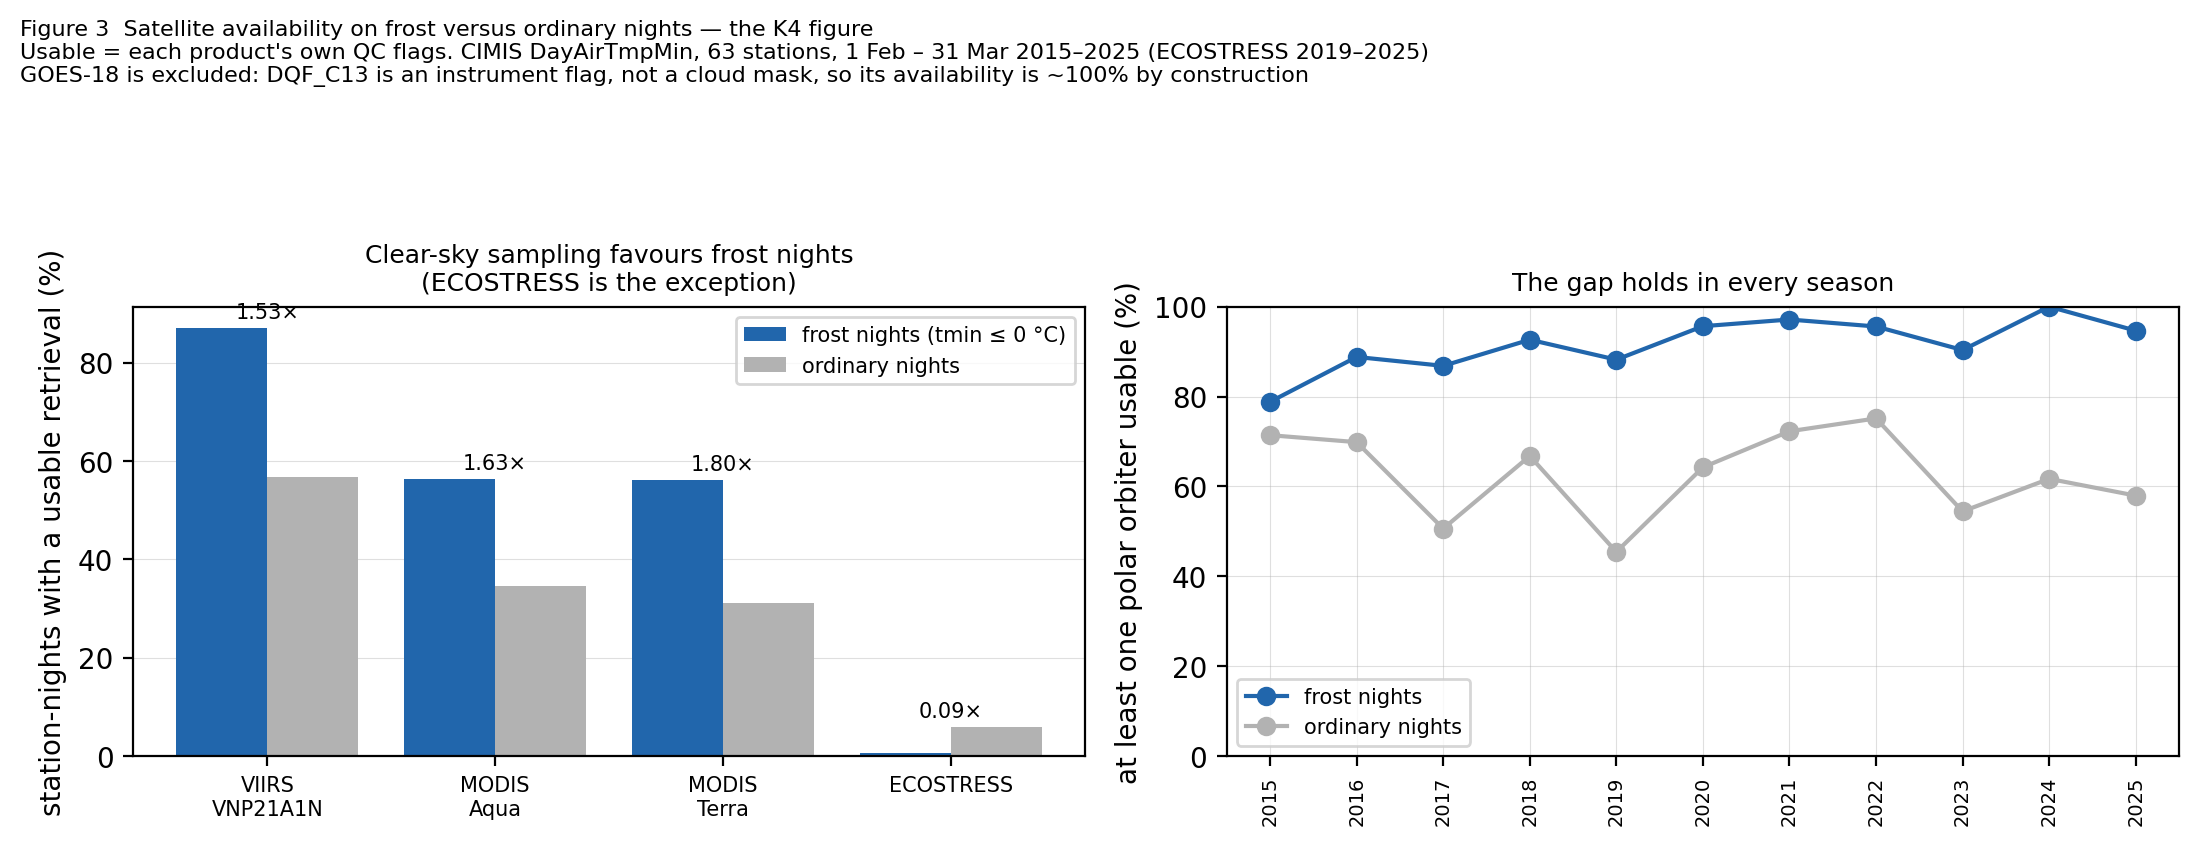

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=200)

ax = axes[0]
prods = POLAR + ["ecostress"]
x = np.arange(len(prods))
fr = [base[base.frost][p].mean() * 100 if p != "ecostress"
      else base[(base.year >= 2019) & base.frost][p].mean() * 100 for p in prods]
nr = [base[~base.frost][p].mean() * 100 if p != "ecostress"
      else base[(base.year >= 2019) & ~base.frost][p].mean() * 100 for p in prods]
ax.bar(x - 0.2, fr, 0.4, label="frost nights (tmin ≤ 0 °C)", color="#2166ac")
ax.bar(x + 0.2, nr, 0.4, label="ordinary nights", color="#b2b2b2")
ax.set_xticks(x)
ax.set_xticklabels([LABEL[p].replace(" ", "\n", 1) for p in prods], fontsize=7.5)
ax.set_ylabel("station-nights with a usable retrieval (%)")
ax.set_title("Clear-sky sampling favours frost nights\n(ECOSTRESS is the exception)", fontsize=9)
ax.legend(fontsize=7.5)
ax.grid(axis="y", lw=0.4, alpha=0.4)
ax.set_axisbelow(True)
for xi, (a, b) in enumerate(zip(fr, nr)):
    ax.text(xi, max(a, b) + 2, f"{a / b:.2f}×" if b else "—", ha="center", fontsize=7.5)

ax = axes[1]
by_year = base.groupby("year").apply(
    lambda d: pd.Series({"frost": 100 * d[d.frost].any_polar.mean() if d.frost.any() else np.nan,
                         "nonfrost": 100 * d[~d.frost].any_polar.mean()}), include_groups=False)
ax.plot(by_year.index, by_year.frost, "o-", color="#2166ac", label="frost nights")
ax.plot(by_year.index, by_year.nonfrost, "o-", color="#b2b2b2", label="ordinary nights")
ax.set_ylim(0, 100)
ax.set_xticks(by_year.index)
ax.set_xticklabels(by_year.index, rotation=90, fontsize=7)
ax.set_ylabel("at least one polar orbiter usable (%)")
ax.set_title("The gap holds in every season", fontsize=9)
ax.legend(fontsize=7.5)
ax.grid(lw=0.4, alpha=0.4)
ax.set_axisbelow(True)

fig.suptitle("Figure 3  Satellite availability on frost versus ordinary nights — the K4 figure\n"
             "Usable = each product's own QC flags. CIMIS DayAirTmpMin, 63 stations, "
             "1 Feb – 31 Mar 2015–2025 (ECOSTRESS 2019–2025)\n"
             "GOES-18 is excluded: DQF_C13 is an instrument flag, not a cloud mask, so its "
             "availability is ~100% by construction",
             fontsize=8, x=0.005, y=0.995, ha="left", va="top")
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.savefig(C.FIGURES / "fig03_availability.png", dpi=200, bbox_inches="tight")
print(f"Figure 3: {len(base):,} station-nights, {int(base.frost.sum()):,} frost, "
      f"{len(POLAR) + 1} products")
print("saved figures/fig03_availability.png")

In [7]:
base.to_csv(C.DERIVED / "03_availability_station_nights.csv", index=False)
avail.to_csv(C.DERIVED / "03_availability_table.csv", index=False)
thr_table.to_csv(C.DERIVED / "03_availability_by_threshold.csv", index=False)
filt_table.to_csv(C.DERIVED / "03_screen_removals.csv", index=False)
eco_table.to_csv(C.DERIVED / "03_ecostress_decomposition.csv", index=False)

print("=" * 78)
print("STEP 3 CHECKPOINT SUMMARY — every figure with its denominator")
print("=" * 78)
print(f"usable CIMIS station-nights                     {len(base):>8,}")
print(f"  frost nights at 0 °C                          {int(base.frost.sum()):>8,}")
for p in POLAR:
    s = base[base.frost]
    print(f"    observed by {LABEL[p]:<18}          {int(s[p].sum()):>8,}   "
          f"({100 * s[p].mean():.1f}%)")
print(f"    observed by at least one polar orbiter      "
      f"{int(base[base.frost].any_polar.sum()):>8,}   "
      f"({100 * base[base.frost].any_polar.mean():.1f}%)")
print(f"  ECOSTRESS frost station-nights in swath (2019+) "
      f"{int(base[(base.year >= 2019) & base.frost].lst_raw_k.notna().sum()):>6,}")
print(f"K4 (polar orbiters)                               {'DOES NOT FIRE':>8}")
print(f"K4 (ECOSTRESS, orbital)                                   {'FIRES':>8}")
print("\nwrote data/derived/: 03_availability_station_nights.csv, 03_availability_table.csv,")
print("      03_availability_by_threshold.csv, 03_screen_removals.csv,")
print("      03_ecostress_decomposition.csv; figures/fig03_availability.png")

STEP 3 CHECKPOINT SUMMARY — every figure with its denominator
usable CIMIS station-nights                       31,359
  frost nights at 0 °C                             2,910
    observed by VIIRS VNP21A1N                 2,532   (87.0%)
    observed by MODIS Aqua                     1,638   (56.3%)
    observed by MODIS Terra                    1,633   (56.1%)
    observed by at least one polar orbiter         2,676   (92.0%)
  ECOSTRESS frost station-nights in swath (2019+)     10
K4 (polar orbiters)                               DOES NOT FIRE
K4 (ECOSTRESS, orbital)                                      FIRES

wrote data/derived/: 03_availability_station_nights.csv, 03_availability_table.csv,
      03_availability_by_threshold.csv, 03_screen_removals.csv,
      03_ecostress_decomposition.csv; figures/fig03_availability.png
